# Least-squares refinement: tuning evolved bores exactly

An evolution (`CMAES` or `Nuevolution`) finds a good bore, but its peaks usually end up a few cent away from
the targets: the last step down into the minimum is slow for a random search. `refine_least_squares` takes
that last step with a gradient-based method. It changes the genome until the peaks sit on their targets,
typically within a few hundred loss evaluations.

How it works, in short:

* The tuning losses are sums of absolute deviations, $\sum_i w_i\,|c_i|/600$ with $c_i$ the deviation of a
  peak in cent. They have a kink exactly at the target, which makes gradient methods overshoot. Instead,
  `refine_least_squares` minimizes the sum of the squared **signed** deviations (the *residuals*), which is
  smooth there. `FrequencyTuningLoss` and `ScaleTuningLoss` provide these residuals.
* It uses scipy's trust-region-reflective least squares (a Gauss-Newton / Levenberg-Marquardt variant) inside
  the genome box $[0, 1]$.
* The Jacobian comes from finite differences: one extra evaluation per gene, run in parallel threads. No
  PyTorch or other autodiff library is needed, because the loss is smooth at the scale of these tiny steps.

The experiment behind the design is in [gradient_refinement.ipynb](gradient_refinement.ipynb).

Contents:

1. Setup
2. Basic use: refine the result of an evolution
3. Refining a population, with a scale
4. Shorter evolution + refinement vs. a long evolution
5. When (not) to use it

In [1]:
import sys
sys.path.insert(0, "../../src")

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from didgelab import (
    CMAES,
    CompositeTairuaLoss,
    FrequencyTuningLoss,
    KigaliShape,
    PeakQuantityLoss,
    ScaleTuningLoss,
    refine_least_squares,
    refine_population,
)
from didgelab.acoustical_simulation import acoustical_simulation
from didgelab.app import init_app
from didgelab.shapes.MbeyaShape import MbeyaGenome

init_app("least_squares_refinement", create_output_folder=False)
logging.disable(logging.WARNING)

## 2. Basic use

Target: a drone on D2 and three toots on F#3, D4 and G4, with the drone weighted twice. CMA-ES searches a
Kigali bore for 1500 loss evaluations, then `refine_least_squares` gets up to 500 more.

In [2]:
TARGETS_HZ = np.array([73.4, 185.0, 293.7, 392.0])  # D2, F#3, D4, G4


def tuning_loss():
    loss = CompositeTairuaLoss()
    loss.add_component("freq", FrequencyTuningLoss(np.log2(TARGETS_HZ), np.full(4, -1.0), [2.0, 1.0, 1.0, 0.5]))
    return loss


def target_deviations(loss, genome):
    # Deviation in cent of the peak nearest to each target
    _, spectrum = loss.analyze(genome)
    peaks = spectrum["peak_freqs_log"]
    return np.array([1200 * (peaks[np.argmin(np.abs(peaks - t))] - t) for t in np.log2(TARGETS_HZ)])


np.random.seed(1)
loss = tuning_loss()
evolved = CMAES(loss, KigaliShape(), num_generations=1500 // 16, population_size=16).evolve()[0]
refined = refine_least_squares(loss, evolved, max_evaluations=500)

print(f"loss after the evolution:  {evolved.loss['total']:.2e}")
print(f"loss after the refinement: {refined.loss['total']:.2e} "
      f"({refined.named_parameters['refine_evaluations']} evaluations)")
pd.DataFrame({
    "target (Hz)": TARGETS_HZ,
    "after evolution (cent)": target_deviations(loss, evolved),
    "after refinement (cent)": target_deviations(loss, refined),
}).style.format({"target (Hz)": "{:.1f}", "after evolution (cent)": "{:+.3f}", "after refinement (cent)": "{:+.4f}"})

loss after the evolution:  2.18e-02
loss after the refinement: 1.08e-08 (500 evaluations)


,target (Hz),after evolution (cent),after refinement (cent)
0,73.4,+1.459,+0.0000
1,185.0,-2.129,+0.0000
2,293.7,-3.968,+0.0000
3,392.0,+8.099,+0.0000


The refinement changes the bore only slightly. The plot shows both bores and the impedance around each target
(± 30 cent); the dashed line is the target.

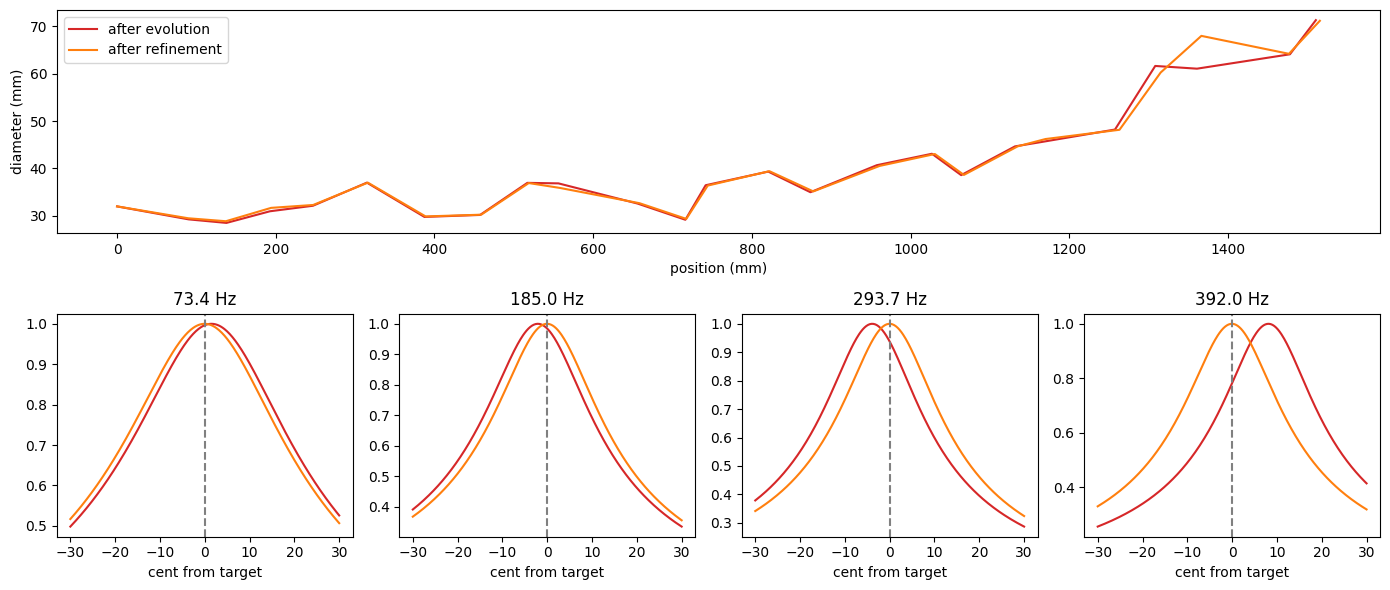

In [3]:
fig = plt.figure(figsize=(14, 6))
ax_bore = fig.add_subplot(2, 1, 1)
for genome, label, color in [(evolved, "after evolution", "tab:red"), (refined, "after refinement", "tab:orange")]:
    x, d = np.array(genome.genome2geo().geo).T
    ax_bore.plot(x, d, color=color, label=label)
ax_bore.set_xlabel("position (mm)")
ax_bore.set_ylabel("diameter (mm)")
ax_bore.legend()

for k, target in enumerate(TARGETS_HZ):
    ax = fig.add_subplot(2, 4, 5 + k)
    freqs = target * 2 ** (np.linspace(-30, 30, 301) / 1200)
    for genome, color in [(evolved, "tab:red"), (refined, "tab:orange")]:
        z = np.asarray(acoustical_simulation(genome.genome2geo(), freqs))
        ax.plot(1200 * np.log2(freqs / target), z / z.max(), color=color)
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_title(f"{target:.1f} Hz")
    ax.set_xlabel("cent from target")
plt.tight_layout()
plt.show()

## 3. Refining a population, with a scale

`refine_population` refines the best few genomes of a population in parallel; with
`method="least-squares"` it uses `refine_least_squares`. Here the loss also pulls all other resonances
towards D minor pentatonic (`ScaleTuningLoss`, which provides residuals too) and asks for six peaks
(`PeakQuantityLoss`, which has no residuals: it enters the least-squares problem as $\sqrt{L}$ and is constant
near a good bore anyway).

In [4]:
def scale_loss():
    loss = tuning_loss()
    loss.add_component("scale", ScaleTuningLoss(62, [0, 3, 5, 7, 10], weight=2.0))
    loss.add_component("peaks_qty", PeakQuantityLoss(target_count=6, weight=1.0))
    return loss


np.random.seed(2)
loss = scale_loss()
population = CMAES(loss, KigaliShape(), num_generations=1500 // 16, population_size=16, keep=10).evolve()
refined_population = refine_population(loss, population, n_best=4, max_evaluations=500, method="least-squares")

pd.DataFrame({
    "before": [g.loss["total"] for g in population[:4]],
    "after": [g.loss["total"] for g in refined_population[:4]],
}, index=[f"rank {i + 1}" for i in range(4)]).style.format("{:.4f}")

,before,after
rank 1,0.1716,0.1227
rank 2,0.1782,0.1280
rank 3,0.1785,0.1481
rank 4,0.1814,0.1483


## 4. Shorter evolution + refinement vs. a long evolution

The refinement is fast at the last step, so the evolution can stop earlier. We compare, on two shapes and five
seeds:

* **CMA-ES 3000**: CMA-ES alone for 3000 evaluations,
* **CMA-ES 1000 + LSQ**: CMA-ES for 1000 evaluations, then `refine_least_squares` with up to 500 (1500 in total),
* **CMA-ES 1500 + LSQ**: CMA-ES for 1500, then up to 500 (2000 in total).

The table shows the worst deviation of the four targets in cent (median over the seeds) and the evaluations used.

In [5]:
SHAPES = {"Kigali": lambda: KigaliShape(), "Mbeya": lambda: MbeyaGenome(n_bubbles=2)}
SEEDS = [1, 2, 3, 4, 5]
STRATEGIES = {"CMA-ES 3000": (3000, 0), "CMA-ES 1000 + LSQ": (1000, 500), "CMA-ES 1500 + LSQ": (1500, 500)}

rows = []
for shape_name, make_shape in SHAPES.items():
    for strategy, (evolution, refinement) in STRATEGIES.items():
        for seed in SEEDS:
            np.random.seed(seed)
            loss = tuning_loss()
            best = CMAES(loss, make_shape(), num_generations=evolution // 16, population_size=16).evolve()[0]
            used = evolution // 16 * 16
            if refinement:
                best = refine_least_squares(loss, best, max_evaluations=refinement)
                used += best.named_parameters["refine_evaluations"]
            rows.append({"shape": shape_name, "strategy": strategy, "seed": seed,
                         "worst cent": np.abs(target_deviations(loss, best)).max(), "evaluations": used})
comparison = pd.DataFrame(rows)
comparison.groupby(["shape", "strategy"], sort=False)[["worst cent", "evaluations"]].median() \
    .style.format({"worst cent": "{:.3f}", "evaluations": "{:.0f}"})

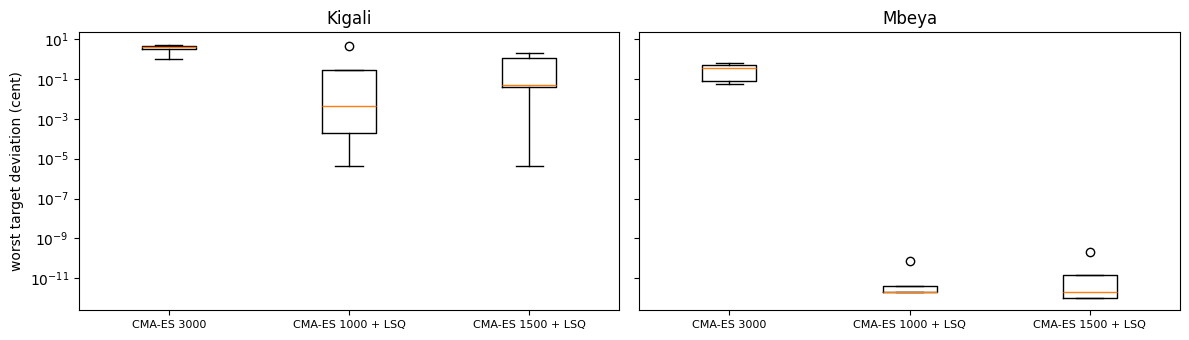

In [6]:
fig, axes = plt.subplots(1, len(SHAPES), figsize=(12, 3.5), sharey=True)
for ax, shape_name in zip(axes, SHAPES):
    data = [comparison[(comparison["shape"] == shape_name) & (comparison["strategy"] == s)]["worst cent"]
            for s in STRATEGIES]
    ax.boxplot(data)
    ax.set_xticks(range(1, len(STRATEGIES) + 1), list(STRATEGIES), fontsize=8)
    ax.set_yscale("log")
    ax.set_title(shape_name)
axes[0].set_ylabel("worst target deviation (cent)")
plt.tight_layout()
plt.show()

**A short evolution plus refinement beats a long evolution.** With CMA-ES for 1000 evaluations and the
refinement on top (about 1100-1500 evaluations in total) the worst target deviation is 0.004 cent on the Kigali
shape and practically zero on the Mbeya shape (medians). CMA-ES alone needs twice as many evaluations and still
ends 4.1 and 0.36 cent off. Running the evolution longer before refining (1500 + LSQ) does not help further.

The refinement does not fix everything: in one of the five Kigali runs a target stays about 5 cent off. There
the evolution had stopped in a different local minimum, and the refinement only finds the nearest one.
Refining several genomes with `refine_population` makes such a miss less likely.

## 5. When (not) to use it

* **Use it** when the loss is mostly tuning: `FrequencyTuningLoss` and `ScaleTuningLoss`. These provide signed
  residuals.
* **Do not expect much** from it for losses dominated by components without residuals (peak count, Q factor,
  harmonic splitting, modal density, ...). They enter as $\sqrt{L_k}$ and keep their kinks; for the full
  eleven-component loss, continuing the evolution worked better in the
  [experiment](gradient_refinement.ipynb).
* **Start from a good genome.** The refinement only finds the *nearest* local minimum. It does not move a peak
  to a different target or create a missing one; that is the job of the evolution.
* **Cost:** one Jacobian costs `n_genes + 1` evaluations (50 for the Kigali shape, 18 for Mbeya), run in
  parallel threads. `max_evaluations` bounds the total; the method also stops early when it has converged.
* The finite-difference step `fd_step` (default $10^{-6}$ in genome units) rarely needs changing: the gradient
  is accurate for steps between about $10^{-9}$ and $10^{-5}$.